# CHURNSHIELD-AGENT
La metodologia empleada para este proyecto es CRISP-ML(Q), la cual describe seis fases:
- Business and Data Understanding
- Data Engineering (Data Preparation)
- Machine Learning Model Engineering
- Quality Assurance for Machine Learning Applications
- Deployment
- Monitoring and Maintenance.

Este notebook cubre las dos primeras fases: Business and Data Understanding y Data Engineering.

## Logica de negocio y entendimiento del dataset
La perdida de clientes, en adelante churn, es uno de los retos de las empresas de telecomunicaciones. Identificar a los clientes con mayor probabilidad de darse de baja permite tomar medidas preventivas, como ofrecer descuentos, mejorar la atencion o proponer planes personalizados.

El dataset IBM Telco Customer Churn contiene información sobre clientes de una empresa de telecomunicaciones, incluyendo datos demográficos, detalles de cuenta, servicios, facturacion y metodos de pago. El objetivo del proyecto es ordenar a los clientes segun su riesgo de churn y obtener probabilidades que puedan usarse en una decision de retencion.


## Situacion del problema
Las empresas de telecomunicaciones pierden ingresos cuando los clientes cancelan sus servicios. La empresa desea identificar a los clientes con mayor riesgo para aplicar estrategias proactivas de retencion.

El modelo estima la probabilidad de churn. La decision operativa no consiste solo en clasificar a todos los clientes, sino en ordenar el 15 por ciento superior y usar las probabilidades estimadas en el calculo de utilidad. Una predicción util debe combinar buen ordenamiento de riesgo con probabilidades razonablemente calibradas.


## Problema de Machine Learning
El problema es de aprendizaje supervisado porque el conjunto de datos contiene ejemplos etiquetados. También es un problema de clasificacion binaria, ya que la variable objetivo `Churn Value` toma los valores 0 y 1.

El proposito del modelo es estimar el riesgo de churn a partir de los predictores permitidos por la configuración del agente.


# Cargar librerías

In [130]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split

# Cargar el dataset

In [131]:
df_original = pd.read_excel('Telco_customer_churn.xlsx')

## Vista general del dataset

In [132]:
df_original.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [133]:
df_original.tail()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN
7042,3186-AJIEK,1,United States,California,Apple Valley,92308,"34.424926, -117.184503",34.424926,-117.184503,Male,...,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No,0,38,5097,NaN


In [134]:
df_original.shape

(7043, 33)

# Análisis del dataset

In [135]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [136]:
df_original.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [137]:
df_original.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

In [138]:
df_original.dtypes

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges         object
Churn Label              str
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason             str
dtype: object

`Total Charges` contiene algunos valores que no se leen como numeros. Se convertira a formato numerico y los faltantes se imputaran con 0, conservando las filas como indica la configuración del agente. Se trabajara sobre una copia del dataframe original.


In [139]:
df = df_original.copy()

In [140]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

In [141]:
df.dtypes

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges        float64
Churn Label              str
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason             str
dtype: object

# Limpieza del dataset

En esta sección se eliminan los registros duplicados (si es que hay)

In [142]:
df.duplicated().sum()

np.int64(0)

Como no hay duplicados no se puede hacer más nada en esta parte

In [143]:
print(df.isnull().sum())

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges          11
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64


In [144]:
# Se eliminan del dataframe de trabajo las columnas que no pueden ser usadas
# como predictores. Churn Value se conserva como variable objetivo.
df = df.drop(columns=[
    'CustomerID',
    'Count',
    'Country',
    'State',
    'City',
    'Lat Long',
    'Latitude',
    'Longitude',
    'Zip Code',
    'Churn Label',
    'Churn Score',
    'Churn Reason',
])


Las columnas eliminadas no se borran del archivo original. Solo se retiran del dataframe usado en este notebook.

- `CustomerID` es un identificador.
- `Count` es un campo administrativo.
- Los campos de pais, estado, ciudad, codigo postal, latitud, longitud y `Lat Long` describen ubicacion y no forman parte del modelo.
- `Churn Label`, `Churn Score` y `Churn Reason` contienen información derivada del resultado y producirian fuga de información.
- `Gender` y `Senior Citizen` se conservan para el análisis descriptivo, pero se excluyen del modelo por ser variables sensibles.
- Las variables de servicios excluidas por diseño se pueden revisar de forma descriptiva, pero no entran en la matriz de diseño.


# EDA

## Análisis de la variable objetivo

En nuestro dataset, la variable objetivo es **Churn Value** donde 1 es que el cliente se retiró/cambió a otro proveedor, mientras que 0 si no se ha retirado.

Primero se analizarán la proporción de clientes que se retiraron vs los que no

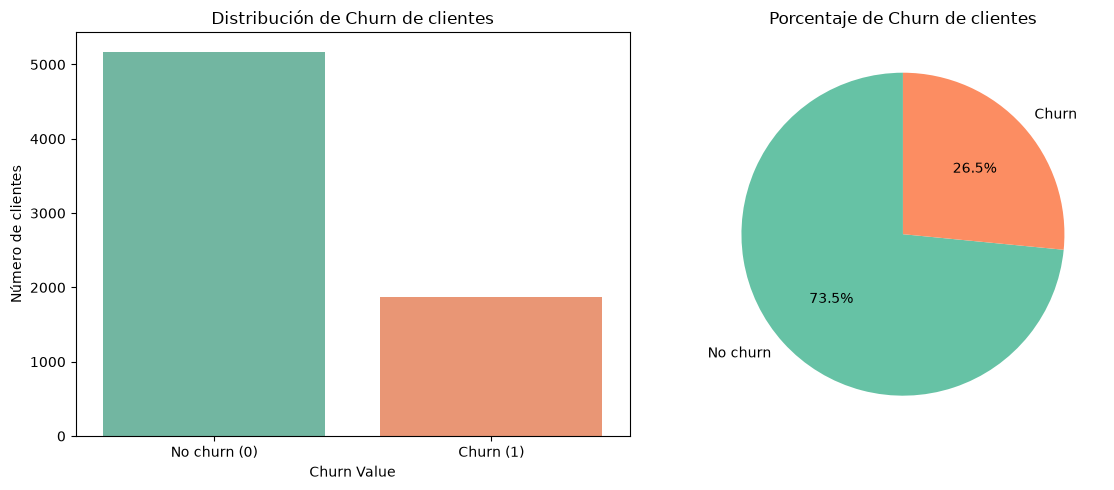

In [145]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# --- contar los valores
sns.countplot(
    x='Churn Value',
    hue='Churn Value',
    data=df,
    palette='Set2',
    legend=False,
    ax=ax[0]
)

ax[0].set_title("Distribución de Churn de clientes")
ax[0].set_xlabel("Churn Value")
ax[0].set_ylabel("Número de clientes")
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(["No churn (0)", "Churn (1)"])

# --- piechart
df['Churn Value'].value_counts().plot(
    kind='pie',
    labels=["No churn", "Churn"],
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('Set2'),
    ax=ax[1]
)

ax[1].set_title("Porcentaje de Churn de clientes")
ax[1].set_ylabel("")

# Adjust spacing
plt.tight_layout()

# Show both plots
plt.show()

Se puede apreciar que la proporción de clientes que "churnearon" es del 26.6%, por lo que el porcentaje de datos que se usan para validar el entrenamiento puede abarcar más de la proporción de la variable objetivo, suponiendo un riesgo de que la totalidad de esta proporción se encuentre solamente en la sección de pruebas.

## Análisis demográfico
Las variables demograficas permiten describir la cartera y revisar diferencias en la tasa de churn por categoria. Se analizaran `Gender`, `Senior Citizen`, `Partner` y `Dependents`.

`Gender` y `Senior Citizen` se excluyen del modelo por ser variables sensibles. Esta exclusion es una decision de gobernanza y no significa que carezcan de relación con el churn. Si se observa una diferencia entre categorías, se reportara como señal descriptiva y como posible costo de excluirlas del modelo.


In [146]:
df.columns

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Value',
       'CLTV'],
      dtype='str')

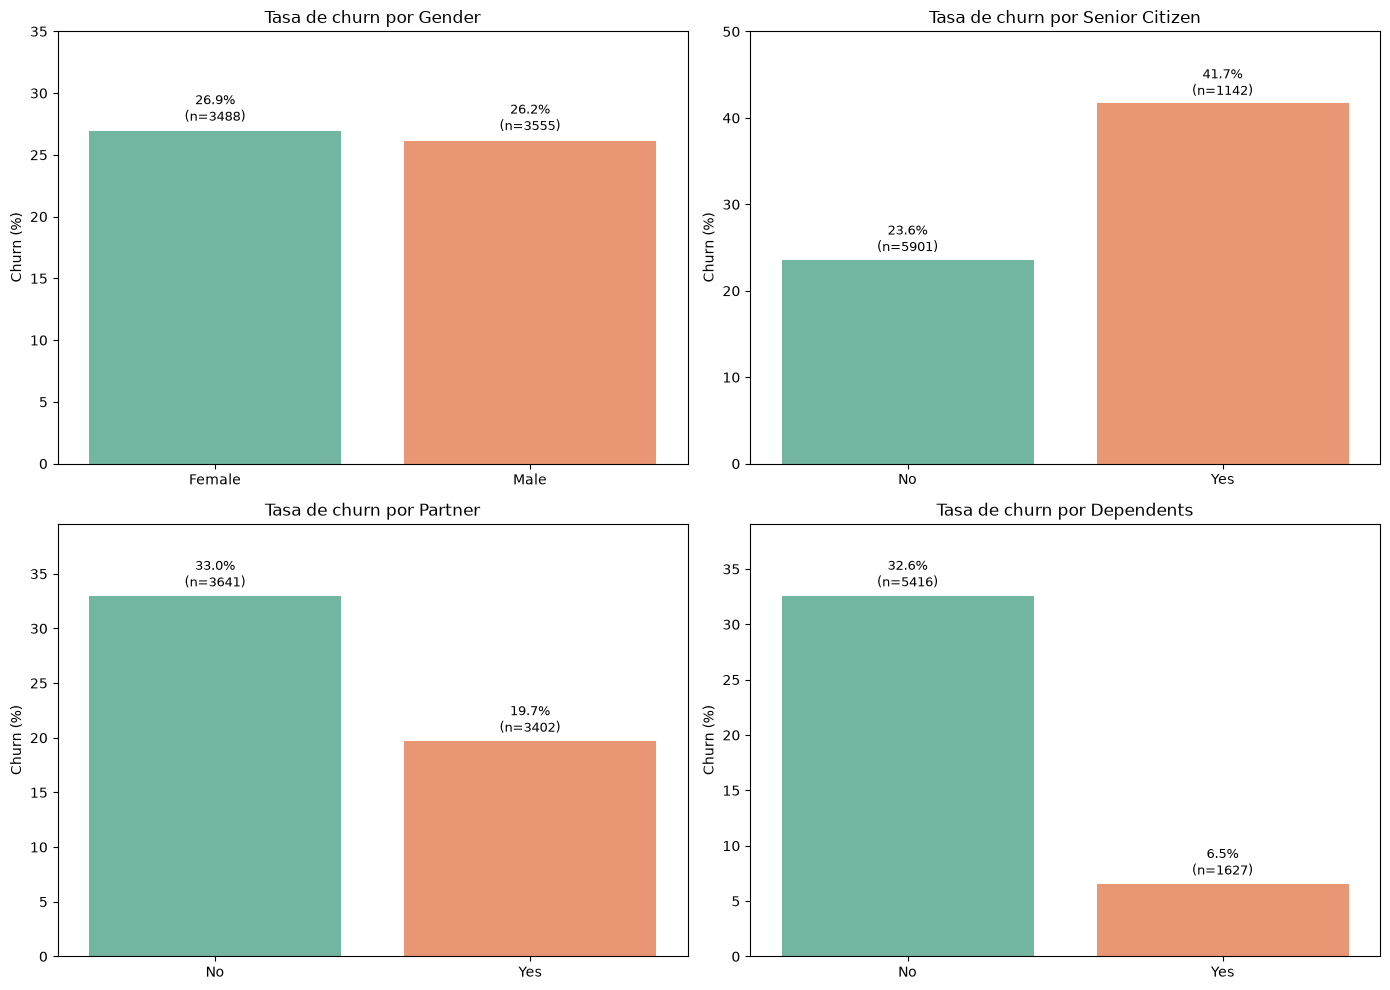


Gender
Gender  clientes  churners  tasa_churn tasa_churn_pct
Female      3488       939    0.269209          26.92
  Male      3555       930    0.261603          26.16

Senior Citizen
Senior Citizen  clientes  churners  tasa_churn tasa_churn_pct
            No      5901      1393    0.236062          23.61
           Yes      1142       476    0.416813          41.68

Partner
Partner  clientes  churners  tasa_churn tasa_churn_pct
     No      3641      1200    0.329580          32.96
    Yes      3402       669    0.196649          19.66

Dependents
Dependents  clientes  churners  tasa_churn tasa_churn_pct
        No      5416      1763    0.325517          32.55
       Yes      1627       106    0.065151           6.52


In [147]:
demograficas = ['Gender', 'Senior Citizen', 'Partner', 'Dependents']

fig, axis = plt.subplots(2, 2, figsize=(14, 10))
for eje, variable in zip(axis.ravel(), demograficas):
    tabla = df.groupby(variable, dropna=False)['Churn Value'].agg(
        clientes='size', churners='sum', tasa_churn='mean'
    ).reset_index()
    tabla['tasa_churn_pct'] = tabla['tasa_churn'] * 100
    sns.barplot(data=tabla, x=variable, y='tasa_churn_pct', hue=variable,
                legend=False, ax=eje, palette='Set2')
    eje.set_title(f'Tasa de churn por {variable}')
    eje.set_xlabel('')
    eje.set_ylabel('Churn (%)')
    eje.set_ylim(0, max(35, tabla['tasa_churn_pct'].max() * 1.2))
    for indice, fila in tabla.iterrows():
        eje.text(indice, fila['tasa_churn_pct'] + 0.5,
                 f"{fila['tasa_churn_pct']:.1f}%\n(n={int(fila['clientes'])})",
                 ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

for variable in demograficas:
    tabla = df.groupby(variable, dropna=False)['Churn Value'].agg(
        clientes='size', churners='sum', tasa_churn='mean'
    ).reset_index()
    tabla['tasa_churn_pct'] = tabla['tasa_churn'] * 100
    print(f'\n{variable}')
    print(tabla.to_string(index=False, formatters={'tasa_churn_pct': '{:.2f}'.format}))


Las tasas permiten comparar categorías con tamaños distintos. Las diferencias observadas son descriptivas y no prueban causalidad. `Gender` y `Senior Citizen` no se usan como predictores aunque puedan mostrar señal, porque se excluyen por ser variables sensibles. `Partner` y `Dependents` si estan permitidas y se evaluaran dentro del modelo.


## Análisis de servicios

En esta sección se analizan los servicios de telecomunicaciones a los que están suscritos los clientes. Comprender el uso de los servicios ayuda a identificar las preferencias de los clientes y la posible relación entre los servicios a los que están suscritos y la pérdida de clientes.

Se analizan las siguientes características relacionadas con el servicio:

- Phone Service (si tiene servicio de telefonía fija)
- Internet Service (si tiene servicio de internet con la compañía y cuál tiene)
- Online Security (si está suscrito a un servicio adicional de seguridad en línea brindado por la compañía)
- Tech Support (si está suscrito a un plan de soporte técnico adicional brindado por la compañía)

Estas funciones brindan información valiosa sobre el comportamiento de los clientes y la adopción de los servicios.

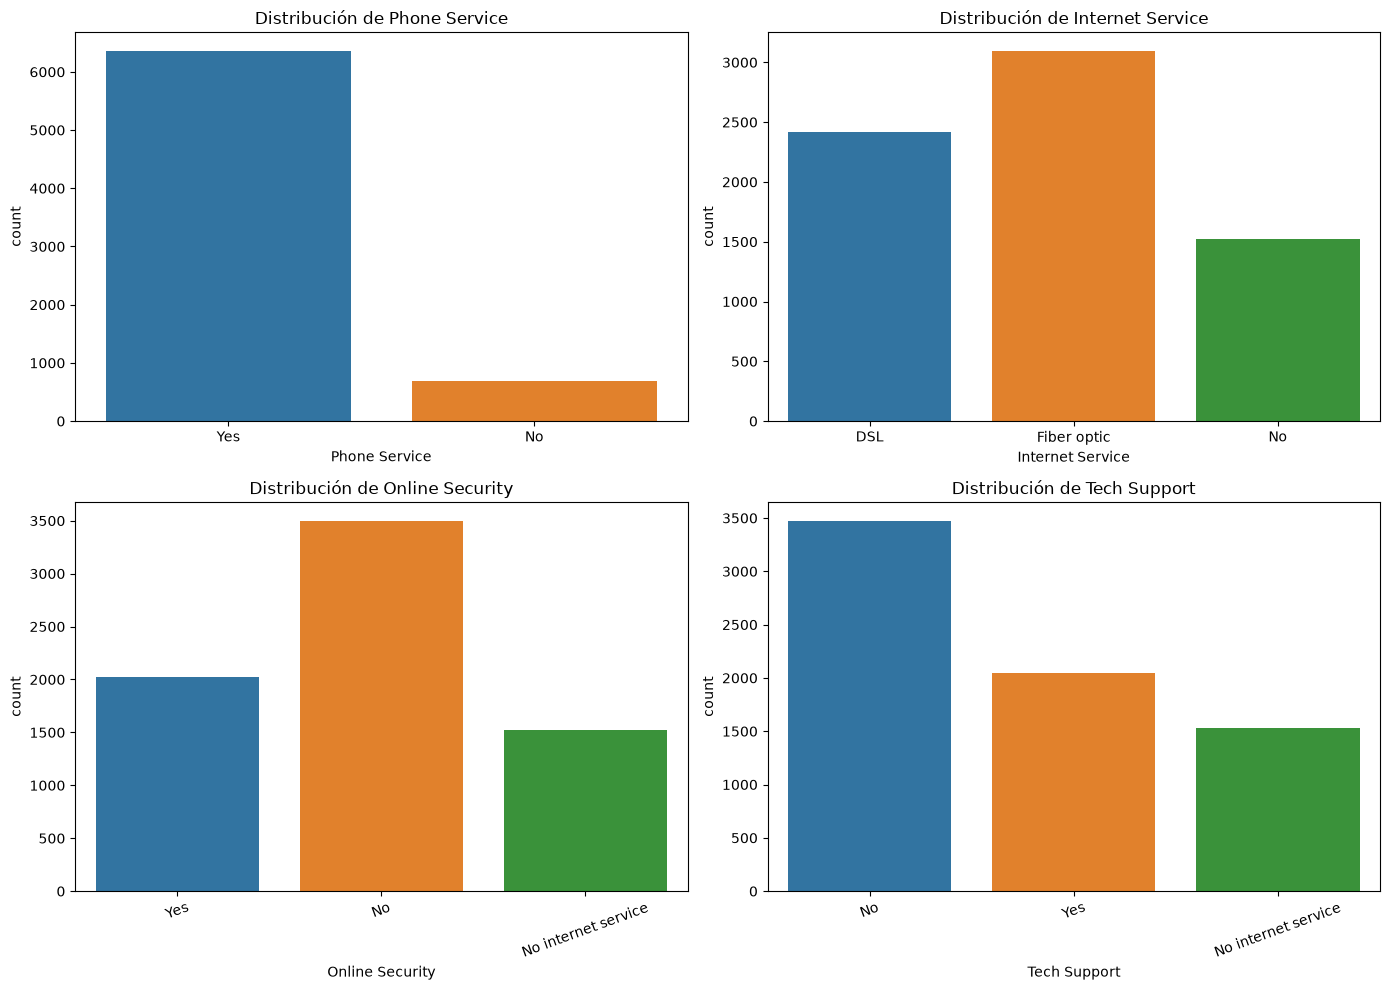

In [148]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Phone Service
sns.countplot(
    x='Phone Service',
    data=df,
    hue='Phone Service',
    ax=axes[0,0]
)
axes[0,0].set_title("Distribución de Phone Service")

# Internet Service
sns.countplot(
    x='Internet Service',
    data=df,
    hue='Internet Service',
    ax=axes[0,1]
)
axes[0,1].set_title("Distribución de Internet Service")

# Online Security
sns.countplot(
    x='Online Security',
    data=df,
    hue='Online Security',
    ax=axes[1,0]
)
axes[1,0].set_title("Distribución de Online Security")
axes[1,0].tick_params(axis='x', rotation=20)

# Tech Support
sns.countplot(
    x='Tech Support',
    data=df,
    hue='Tech Support',
    ax=axes[1,1]
)
axes[1,1].set_title("Distribución de Tech Support")
axes[1,1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

Los conteos describen la composicion de la cartera, pero no bastan para comparar riesgo. Cuando se estudie una categoria se usara también su tasa de churn, calculada como churners dividido entre clientes de esa categoria.


## Tasas de churn por servicio
Los conteos de churn pueden favorecer a las categorias con mas clientes. Por eso se calcula la tasa de churn por categoria para `Internet Service` y se muestra también el tamaño de cada grupo.


Internet Service  clientes  churners  tasa_churn tasa_churn_pct
             DSL      2421       459    0.189591          18.96
     Fiber optic      3096      1297    0.418928          41.89
              No      1526       113    0.074050           7.40


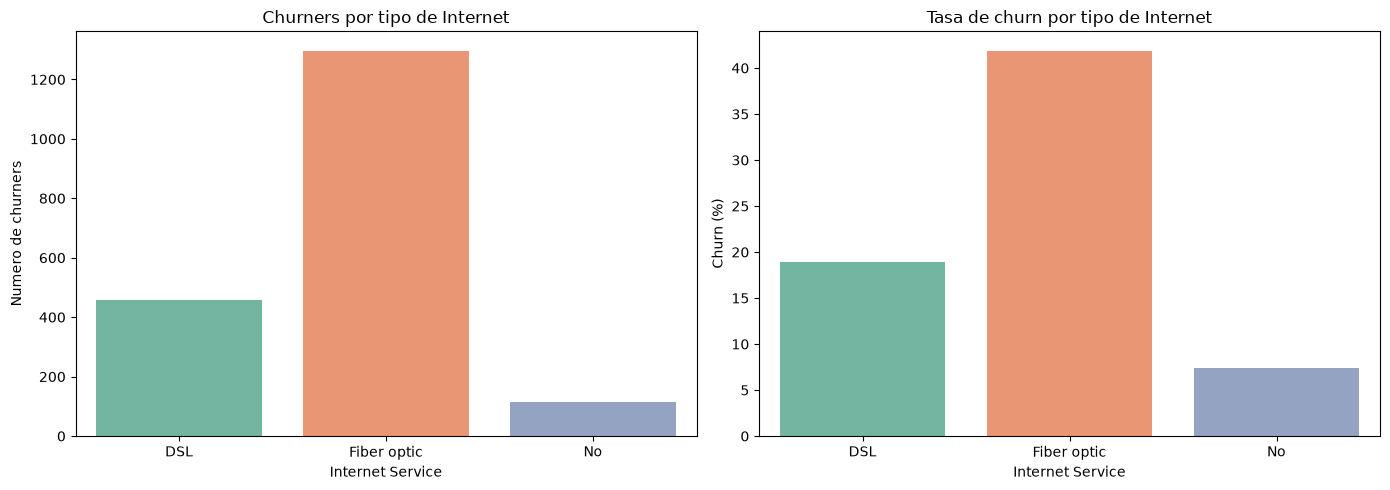

In [149]:
tabla_internet = df.groupby('Internet Service')['Churn Value'].agg(
    clientes='size', churners='sum', tasa_churn='mean'
).reset_index()
tabla_internet['tasa_churn_pct'] = tabla_internet['tasa_churn'] * 100
print(tabla_internet.to_string(index=False, formatters={'tasa_churn_pct': '{:.2f}'.format}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=tabla_internet, x='Internet Service', y='churners', hue='Internet Service', legend=False, ax=axes[0], palette='Set2')
axes[0].set_title('Churners por tipo de Internet')
axes[0].set_xlabel('Internet Service')
axes[0].set_ylabel('Numero de churners')
sns.barplot(data=tabla_internet, x='Internet Service', y='tasa_churn_pct', hue='Internet Service', legend=False, ax=axes[1], palette='Set2')
axes[1].set_title('Tasa de churn por tipo de Internet')
axes[1].set_xlabel('Internet Service')
axes[1].set_ylabel('Churn (%)')
plt.tight_layout()
plt.show()


## Análisis de cuenta de los clientes

Estos datos ofrecen información sobre las preferencias de facturación y los tipos de contrato. Estas características desempeñan un papel importante para comprender el compromiso del cliente y su comportamiento de pago.

Se analizan las siguientes características:

- Contract Type (tipo de contrato)
- Payment Method (método de pago usado)
- Paperless Billing (facturación electrónica)

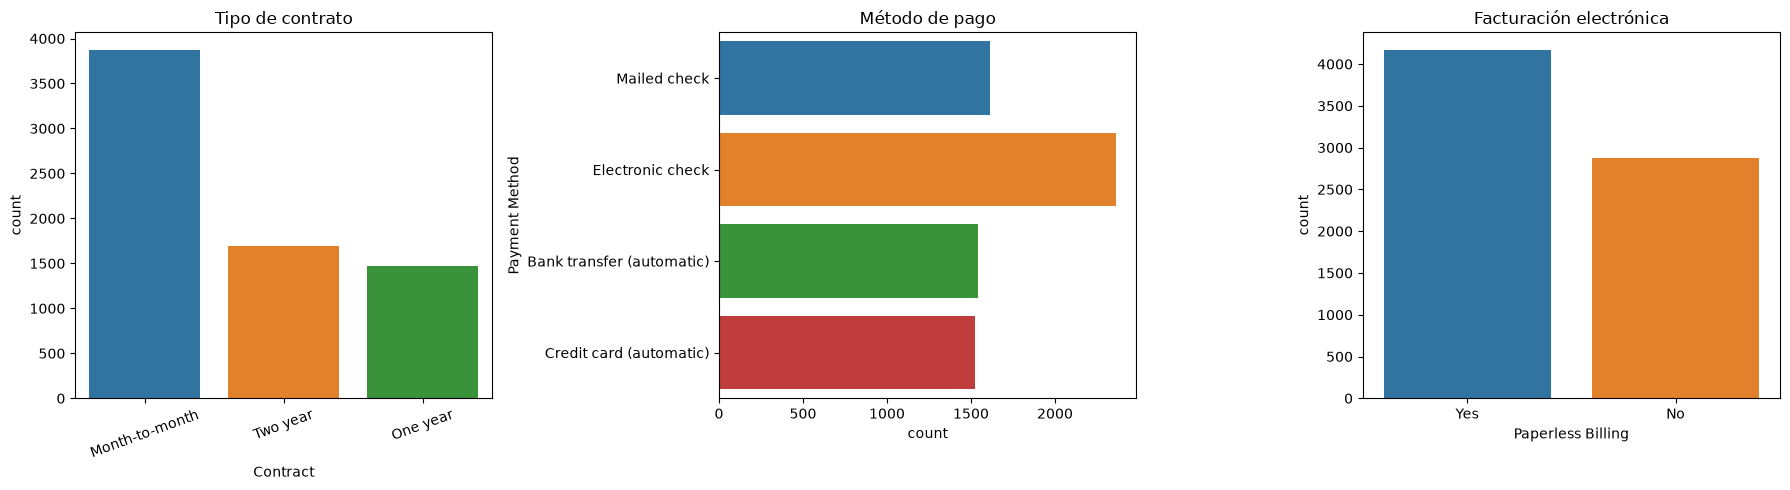

In [150]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Contract
sns.countplot(
    x='Contract',
    data=df,
    hue='Contract',
    ax=axes[0]
)
axes[0].set_title("Tipo de contrato")
axes[0].tick_params(axis='x', rotation=20)

# Payment Method
sns.countplot(
    y='Payment Method',
    data=df,
    hue='Payment Method',
    ax=axes[1]
)
axes[1].set_title("Método de pago")

# Paperless Billing
sns.countplot(
    x='Paperless Billing',
    data=df,
    hue='Paperless Billing',
    ax=axes[2]
)
axes[2].set_title("Facturación electrónica")

plt.tight_layout()
plt.show()

Se puede identificar que la mayoría de los clientes tienen contratos mensuales, que el método de pago más común es el cheque electrónico y que hay más clientes que prefieren la facturación electrónica sobre la normal.

## Análisis de características numéricas

Las variables numéricas describen los patrones de uso y gasto de los clientes.

Se analizan las siguientes características numéricas:

- Tenure Months (meses de antigüedad)
- Monthly Charges (cuotas mensuales)
- Total Charges (total de cargos)

Los histogramas se utilizan para comprender la distribución de estas variables e identificar posibles valores atípicos o asimetrías.

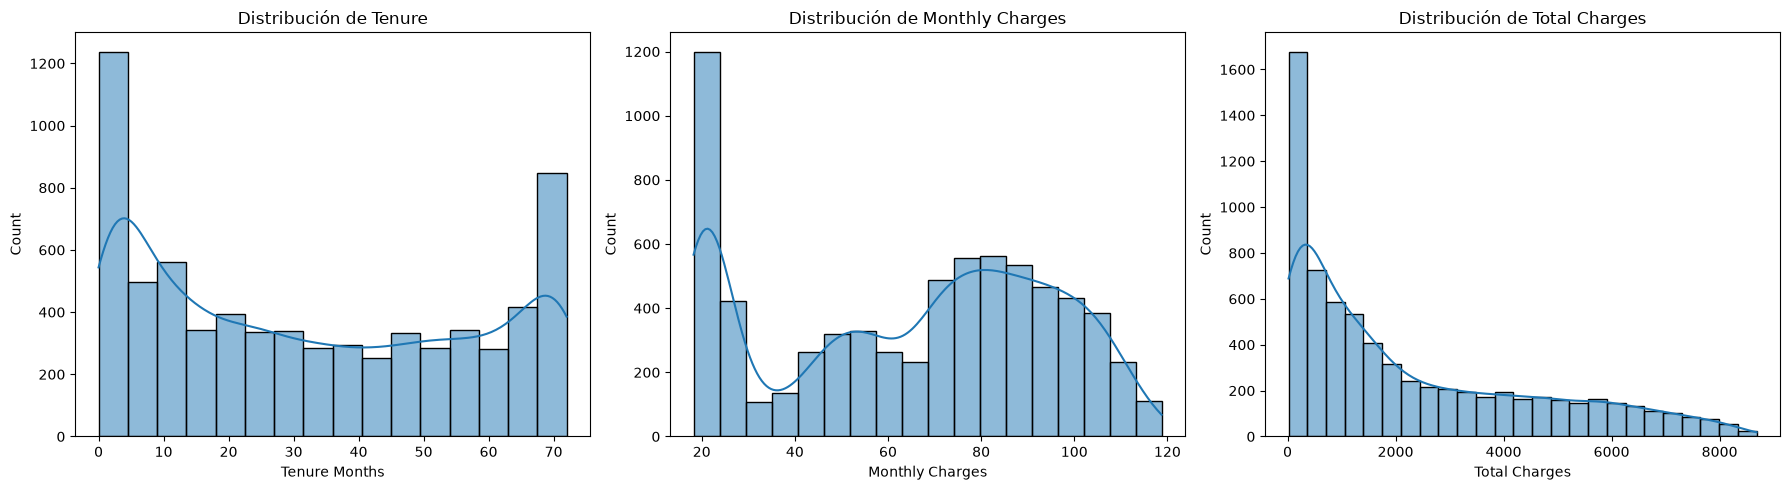

In [151]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Tenure
sns.histplot(
    df['Tenure Months'],
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribución de Tenure")

# Monthly Charges
sns.histplot(
    df['Monthly Charges'],
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribución de Monthly Charges")

# Total Charges
sns.histplot(
    df['Total Charges'],
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Distribución de Total Charges")

plt.tight_layout()
plt.show()

Se puede sacar las siguientes conclusiones de cada variable:

- **Tenure Months:** La distribución no sigue una forma normal. Se observa una alta concentración de clientes con muy pocos meses de permanencia y otro grupo importante con permanencias cercanas al máximo (alrededor de 72 meses), mientras que los valores intermedios presentan menor frecuencia. Esto sugiere una distribución con acumulación en los extremos, coherente con la coexistencia de clientes nuevos y clientes de larga permanencia.
- **Monthly Charges:** La variable presenta una distribución asimétrica y multimodal. Existe un grupo de clientes con cargos mensuales bajos (cercanos a $20), mientras que la mayor concentración de observaciones se encuentra entre aproximadamente $70 y $100. La presencia de varios picos indica que los clientes pueden pertenecer a diferentes planes o paquetes de servicio.
- **Total Charges:** La distribución muestra una fuerte asimetría positiva (sesgo a la derecha). La mayoría de los clientes posee cargos acumulados relativamente bajos, mientras que un número menor alcanza valores muy elevados. Este comportamiento es esperado, ya que el total facturado depende tanto del cargo mensual como del tiempo de permanencia del cliente.

Ninguna de las tres variables presenta una distribución aproximadamente normal.

## Relación entre las características de los clientes y Churn

El objetivo de este análisis es comprender cómo las características clave de los clientes influyen en el comportamiento de deserción.

Se analizan las siguientes relaciones:

- Contract Type vs Churn
- Internet Service vs Churn
- Monthly Charges vs Churn
- Tenure Months vs Churn

Este análisis ayuda a identificar los principales factores que contribuyen a la pérdida de clientes.

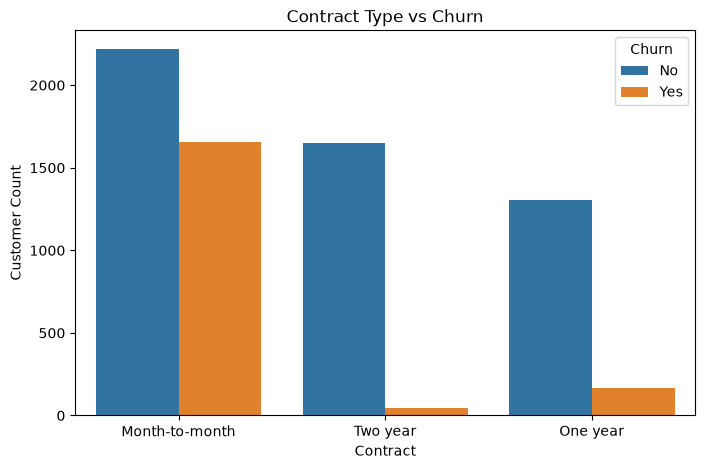

In [152]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Contract',
    hue='Churn Value',
    data=df
)

plt.title("Contract Type vs Churn")
plt.xlabel("Contract")
plt.ylabel("Customer Count")
plt.legend(title="Churn", labels=["No","Yes"])

plt.show()

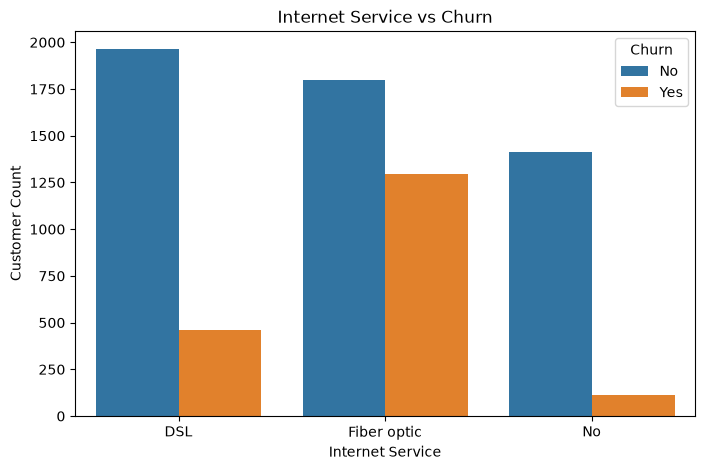

In [153]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Internet Service',
    hue='Churn Value',
    data=df
)

plt.title("Internet Service vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Customer Count")
plt.legend(title="Churn", labels=["No","Yes"])

plt.show()

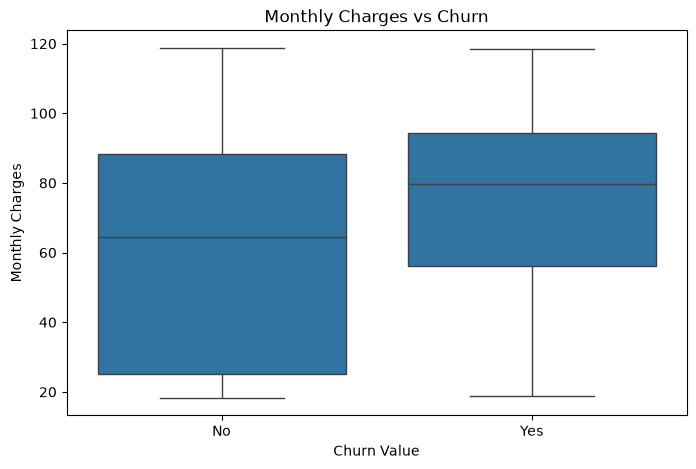

In [154]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Churn Value',
    y='Monthly Charges',
    data=df
)

plt.xticks([0,1],["No","Yes"])

plt.title("Monthly Charges vs Churn")

plt.show()

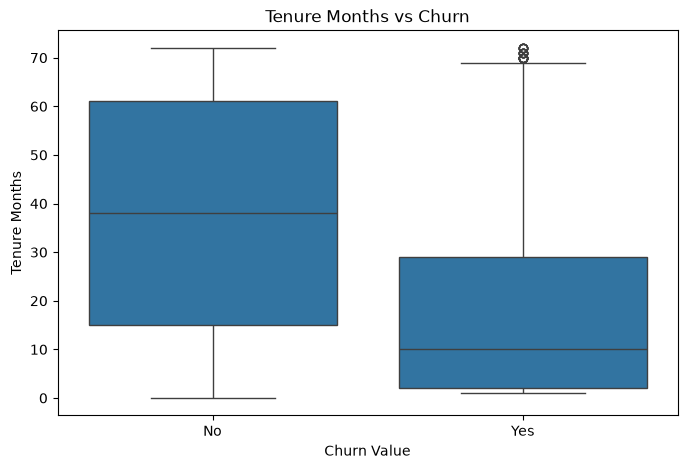

In [155]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Churn Value',
    y='Tenure Months',
    data=df
)

plt.xticks([0,1],["No","Yes"])

plt.title("Tenure Months vs Churn")

plt.show()

Se observan diferencias entre categorías y entre variables numericas, pero cada conclusion debe distinguir entre conteos y tasas.

- Para `Internet Service` se comparan las tasas de churn, no solo el numero total de abandonos. Una categoria grande puede tener mas churners sin tener el mayor riesgo relativo.
- Las facturas mensuales mas elevadas muestran una asociacion descriptiva con el churn, que se contrastara con el modelo.
- Los contratos mensuales muestran una tasa de churn mayor que los contratos de mayor duracion en este dataset.
- La antiguedad presenta una asociacion inversa con el churn en el análisis descriptivo. Esta observacion no prueba causalidad y se evaluara también por su efecto en el ordenamiento del 15 por ciento superior.


## Análisis de correlación

Un mapa de calor de correlación se utiliza para medir la intensidad y la dirección de las relaciones entre variables numéricas.

Los valores de correlación oscilan entre -1 y +1:

- +1 indica una fuerte correlación positiva.
- -1 indica una fuerte correlación negativa.
- 0 indica que no hay correlación lineal.

Esta visualización ayuda a identificar características numéricas altamente correlacionadas que podrían influir en la variable objetivo.

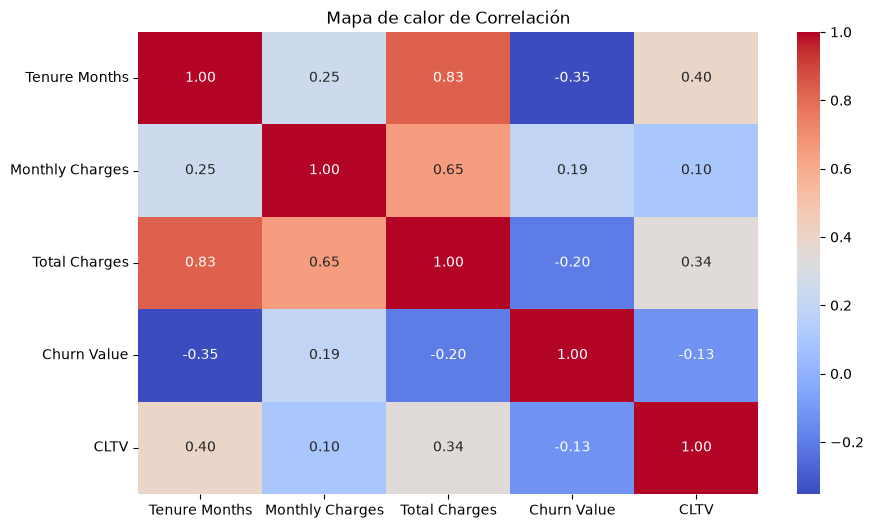

In [156]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(10,6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Mapa de calor de Correlación")

plt.show()

El coeficiente de Pearson muestra una asociacion lineal negativa entre `Tenure Months` y `Churn Value`, y una asociacion positiva debil entre `Monthly Charges` y `Churn Value`. También hay una asociacion alta entre `Tenure Months` y `Total Charges`, algo esperable porque los cargos acumulados dependen del tiempo y del cargo mensual.

Estas correlaciones son indicios exploratorios. Como `Churn Value` es binaria, Pearson no demuestra causalidad ni permite afirmar por si solo cual variable es mas importante. La importancia practica se revisara con la regresion logistica y sus metricas predictivas.


# Validación de supuestos

De acuerdo a lo acordado anteriormente en el [planteamiento del problema](#problema-de-machine-learning), se utilizará el modelo de regresión logística (con posible migración a stacking) para predecir el Churn de clientes. Por lo tanto, lo prudente es validar que se cumplen los supuestos de regresión logística para el dataset. Si algún supuesto falla de forma grave, las conclusiones de negocio y las probabilidades de churn podrían ser engañosas.

| # | Supuesto | Qué exige | Diagnóstico |
|---|----------|-----------|-------------|
| 1 | Observaciones independientes | Ningún registro influye en otro | Diseño del estudio, duplicados |
| 2 | Variable objetivo adecuada | Binaria 0/1 correcta | Inspección del objetivo |
| 3 | Linealidad del logit | Predictores lineales en los log-odds | Box-Tidwell + log-odds empíricos |
| 4 | Sin multicolinealidad grave | Predictores no fuertemente correlacionados | VIF + matriz de correlaciones |
| 5 | Tamaño muestral suficiente | Suficientes eventos por variable | Heurística EPV (>= 10) |
| 6 | Sin atípicos influyentes | Ningún registro sesga el ajuste | Leverage, Cook, DFBETAS |

## Configuración



In [157]:
MUESTRA = 0.3
SEMILLA = 2006

# Estos son exactamente los nueve predictores permitidos por config/agent.yaml.
PREDICTORES = [
    'Partner',
    'Dependents',
    'Internet Service',
    'Contract',
    'Paperless Billing',
    'Payment Method',
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
]
NUMERICAS = ['Tenure Months', 'Monthly Charges', 'Total Charges']
CATEGORICAS = [columna for columna in PREDICTORES if columna not in NUMERICAS]

n_faltantes = int(df['Total Charges'].isna().sum())
df['Total Charges'] = df['Total Charges'].fillna(0.0)
print(f'Valores faltantes de Total Charges imputados con 0: {n_faltantes}')
print('Dimensiones tras limpieza:', df.shape)

X = df[PREDICTORES].copy()
y = df['Churn Value'].astype(int)
ids = df_original['CustomerID'].astype(str)

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, ids, test_size=MUESTRA, random_state=SEMILLA, stratify=y,
)

X_train_dm = pd.get_dummies(X_train, drop_first=True, dtype=float)
X_test_dm = pd.get_dummies(X_test, drop_first=True, dtype=float)
X_test_dm = X_test_dm.reindex(columns=X_train_dm.columns, fill_value=0.0)
X_train_sm = sm.add_constant(X_train_dm, prepend=False)
X_test_sm = sm.add_constant(X_test_dm, prepend=False)
X_test_sm = X_test_sm.reindex(columns=X_train_sm.columns, fill_value=0.0)

print(f'Entrenamiento: {X_train_dm.shape[0]} clientes')
print(f'Prueba: {X_test_dm.shape[0]} clientes')
print(f'Predictores codificados sin intercepto: {X_train_dm.shape[1]}')
print('Columnas del diseño:', list(X_train_dm.columns))


Valores faltantes de Total Charges imputados con 0: 11
Dimensiones tras limpieza: (7043, 21)
Entrenamiento: 4930 clientes
Prueba: 2113 clientes
Predictores codificados sin intercepto: 13
Columnas del diseño: ['Tenure Months', 'Monthly Charges', 'Total Charges', 'Partner_Yes', 'Dependents_Yes', 'Internet Service_Fiber optic', 'Internet Service_No', 'Contract_One year', 'Contract_Two year', 'Paperless Billing_Yes', 'Payment Method_Credit card (automatic)', 'Payment Method_Electronic check', 'Payment Method_Mailed check']


## Matriz de diseño y división entrenamiento / prueba

- Se separa la variable objetivo `Churn Value`.
- División **estratificada** 70/30 con semilla 2006 (misma configuración que los baselines RL/RF ya evaluados). El estratificado no garantiza que la proporción de churners (~26.5 %) se conserve en ambas particiones, sin embargo se eligió mantener esta proporción por dirección del docente.
- Las variables categóricas se codifican con **One-Hot `drop_first=True`**: statsmodels estima el intercepto por separado (`add_constant`), por lo que dejar una categoría de referencia evita la trampa de la multicolinealidad perfecta (dummy trap).
- **Importante:** todos los supuestos se diagnostican sobre el conjunto de entrenamiento; el 30 % de prueba queda intacto para evaluación.

In [158]:
# Solo se prueban las variables numericas que son predictores.
# CLTV se reserva para utilidad y no entra en la regresion logistica.
continuas = ['Tenure Months', 'Monthly Charges', 'Total Charges']


## Ajuste del modelo de referencia (Logit por MLE)

Se ajusta la Regresión Logística por máxima verosimilitud con statsmodels. El resumen permite ver coeficientes, errores estándar, estadísticos z y valores p. 

**Nota:** los p-valores de este resumen evalúan cada coeficiente contra cero, no los supuestos del modelo; los supuestos se prueban en las secciones siguientes.

In [159]:
modelo_logit = sm.Logit(y_train, X_train_sm)
res_logit = modelo_logit.fit(disp=0)

print(res_logit.summary())

                           Logit Regression Results                           
Dep. Variable:            Churn Value   No. Observations:                 4930
Model:                          Logit   Df Residuals:                     4916
Method:                           MLE   Df Model:                           13
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:                  0.3089
Time:                        18:40:53   Log-Likelihood:                -1971.1
converged:                       True   LL-Null:                       -2852.2
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                             coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------
Tenure Months                             -0.0632      0.008     -8.167      0.000      -0.078      -0.048
Monthly Charges                           -0.00

## Evaluación predictiva y calibración
El objetivo principal es ordenar bien el 15 por ciento superior y producir probabilidades utiles para la utilidad. Por eso se reportan `Precision@15`, AUC, Brier y ECE. La curva de calibración compara la probabilidad media estimada con la frecuencia observada en grupos de riesgo.


Precision@15: 0.7120 (k=316)
AUC: 0.8390
Brier: 0.1396
ECE: 0.0215
Log loss: 0.4240


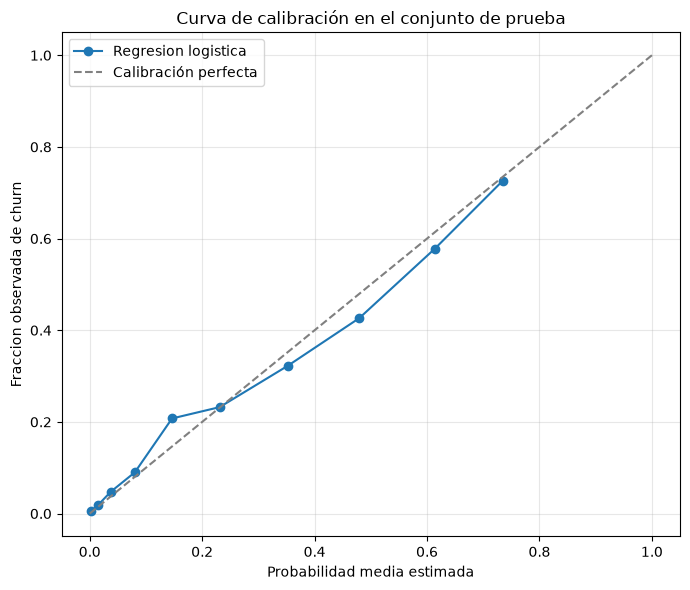

In [160]:
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve

p_test = res_logit.predict(X_test_sm)
p_test = np.clip(np.asarray(p_test), 1e-6, 1 - 1e-6)
orden = np.argsort(-p_test, kind='mergesort')
k_15 = int(np.floor(0.15 * len(y_test)))
seleccion = orden[:k_15]
precision_15 = float(y_test.to_numpy()[seleccion].mean())
auc_test = float(roc_auc_score(y_test, p_test))
brier_test = float(brier_score_loss(y_test, p_test))
logloss_test = float(log_loss(y_test, p_test))

bins = np.quantile(p_test, np.linspace(0, 1, 11))
bins = np.unique(bins)
ece_test = 0.0
for limite_inferior, limite_superior in zip(bins[:-1], bins[1:]):
    mascara = (p_test >= limite_inferior) & (p_test <= limite_superior if limite_superior == bins[-1] else p_test < limite_superior)
    if mascara.any():
        ece_test += mascara.mean() * abs(y_test.to_numpy()[mascara].mean() - p_test[mascara].mean())

print(f'Precision@15: {precision_15:.4f} (k={k_15})')
print(f'AUC: {auc_test:.4f}')
print(f'Brier: {brier_test:.4f}')
print(f'ECE: {ece_test:.4f}')
print(f'Log loss: {logloss_test:.4f}')

fraccion_real, probabilidad_media = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')
plt.figure(figsize=(7, 6))
plt.plot(probabilidad_media, fraccion_real, marker='o', label='Regresion logistica')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Calibración perfecta')
plt.xlabel('Probabilidad media estimada')
plt.ylabel('Fraccion observada de churn')
plt.title('Curva de calibración en el conjunto de prueba')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


La conclusion sobre el desempeño debe basarse en estos valores y no en la inspeccion de los supuestos por si sola. `Precision@15` mide el objetivo de ordenamiento, mientras que Brier y ECE miden la calidad de las probabilidades. La adopcion de un modelo en la utilidad debe considerar las tres perspectivas.


## Comparacion predictiva de formas no lineales
La curvatura observada en `Tenure Months` puede ser importante solo si cambia el objetivo de ranking. Se comparan un modelo lineal y modelos con splines restringidos usando la misma division entrenamiento y prueba. La comparacion es empirica y se centra en `Precision@15`.


In [161]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold


def construir_pipeline(spline_variables):
    lineales = [columna for columna in NUMERICAS if columna not in spline_variables]
    transformadores = []
    if lineales:
        transformadores.append(('numericas_lineales', Pipeline([
            ('imputar', SimpleImputer(strategy='median')),
            ('escalar', StandardScaler()),
        ]), lineales))
    if spline_variables:
        transformadores.append(('numericas_spline', Pipeline([
            ('imputar', SimpleImputer(strategy='median')),
            ('spline', SplineTransformer(n_knots=4, degree=3, include_bias=False)),
            ('escalar', StandardScaler()),
        ]), spline_variables))
    transformadores.append(('categoricas', Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ]), CATEGORICAS))
    preprocesador = ColumnTransformer(transformadores)
    return Pipeline([
        ('preprocesar', preprocesador),
        ('modelo', LogisticRegression(C=1.0, max_iter=2000, solver='lbfgs')),
    ])


# Los tres modelos usan exactamente los mismos cinco pliegues estratificados.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
comparaciones_spline = []
for nombre, spline_variables in [
    ('base_lineal', []),
    ('spline_tenure', ['Tenure Months']),
    ('spline_tenure_monthly', ['Tenure Months', 'Monthly Charges']),
]:
    metricas_fold = []
    for indice_entrenamiento, indice_validacion in cv.split(X_train, y_train):
        pipeline = construir_pipeline(spline_variables)
        X_entrenamiento = X_train.iloc[indice_entrenamiento]
        X_validacion = X_train.iloc[indice_validacion]
        y_entrenamiento = y_train.iloc[indice_entrenamiento]
        y_validacion = y_train.iloc[indice_validacion]
        pipeline.fit(X_entrenamiento, y_entrenamiento)
        probabilidades = pipeline.predict_proba(X_validacion)[:, 1]
        indice = np.argsort(-probabilidades, kind='mergesort')
        k = int(np.floor(0.15 * len(y_validacion)))
        precision = float(y_validacion.to_numpy()[indice[:k]].mean())
        metricas_fold.append({
            'precision_at_15': precision,
            'auc': float(roc_auc_score(y_validacion, probabilidades)),
            'brier': float(brier_score_loss(y_validacion, probabilidades)),
        })
    tabla_folds = pd.DataFrame(metricas_fold)
    comparaciones_spline.append({
        'modelo': nombre,
        'precision_at_15_media': tabla_folds['precision_at_15'].mean(),
        'precision_at_15_sd': tabla_folds['precision_at_15'].std(ddof=1),
        'auc_media': tabla_folds['auc'].mean(),
        'brier_medio': tabla_folds['brier'].mean(),
    })

comparaciones_spline = pd.DataFrame(comparaciones_spline)
print(comparaciones_spline.round(4).to_string(index=False))


               modelo  precision_at_15_media  precision_at_15_sd  auc_media  brier_medio
          base_lineal                 0.7197              0.0265     0.8579       0.1311
        spline_tenure                 0.7224              0.0183     0.8607       0.1299
spline_tenure_monthly                 0.7252              0.0224     0.8615       0.1293


Si una representacion con spline no mejora `Precision@15` en la misma evaluación, la curvatura observada no justifica aumentar la complejidad para este objetivo. Si mejora, se debe considerar en una etapa posterior con validacion cruzada, sin cambiar el resultado del modelo final solo por una particion.


## Supuesto 1 - Observaciones independientes

Exige que ninguna fila del dataset influya en otra. Si hay dependencia (p. ej. medidas repetidas del mismo cliente o clientes del
mismo hogar tratados como independientes), los errores estándar se subestiman y los p-valores quedan artificialmente bajos.

Diagnóstico: la fuente es un **corte transversal** (snapshot de la cartera de clientes), con **una sola fila por cliente** y sin series de tiempo ni grupos definidos (no hay ID de hogar ni de tienda), por lo que la independencia se sostiene por diseño. Se comprueba empíricamente que: no existan filas duplicadas y que `CustomerID` sea único.

Una posible limitación es que las parejas que comparten hogar (`Partner` +  `Dependents`) podrían tener cierta correlación no observable; se documenta como riesgo menor, no se cuantifica (no hay variable de agrupación).

In [162]:
n_duplicados = df_original.duplicated().sum()
n_ids_unicos = df_original["CustomerID"].nunique()
n_filas = len(df_original)

print(f"Filas totales en bruto:\t\t{n_filas}")
print(f"IDs de cliente únicos:\t\t{n_ids_unicos}")
print(f"Filas duplicadas exactas:\t{n_duplicados}")
print(f"Un registro por cliente?:\t{n_ids_unicos == n_filas}")

Filas totales en bruto:		7043
IDs de cliente únicos:		7043
Filas duplicadas exactas:	0
Un registro por cliente?:	True


Como `Filas duplicadas exactas = 0` y los IDs únicos coinciden con el número de filas, cada observación corresponde a un cliente distinto, por lo que el supuesto de independencia es razonable para este dataset.

## Supuesto 2 - Variable objetivo adecuada

Exige que la variable a explicar sea **binaria** (0/1) y que el algoritmo esté bien especificado para esa naturaleza (Logit). Si el objetivo tuviera más de dos niveles o valores inesperados, el modelo sería incorrecto.

Diagnóstico: inspección de valores únicos, conteo y proporción de churners, además de visualización de la distribución.

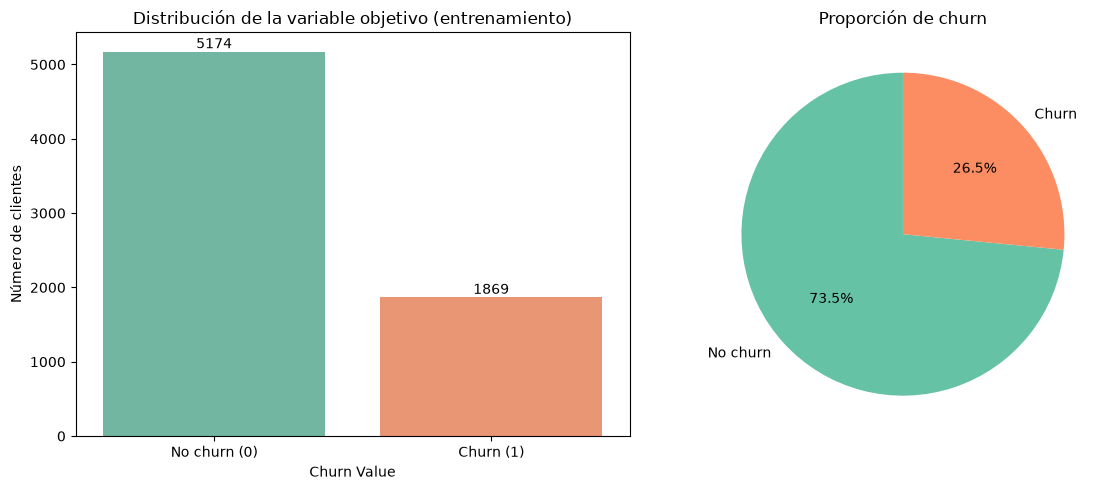

Valores únicos de y:			[0, 1]
¿Binaria (solo 0 y 1)?:			True
Tasa de churn (entrenamiento): 0.2653 = 26.53 %


In [163]:
valores_unicos = [int(v) for v in sorted(y.unique())]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y, hue=y, palette="Set2", legend=False, ax=ax[0])
ax[0].set_title("Distribución de la variable objetivo (entrenamiento)")
ax[0].set_xlabel("Churn Value")
ax[0].set_ylabel("Número de clientes")
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(["No churn (0)", "Churn (1)"])
for contenedor in ax[0].containers:
    ax[0].bar_label(contenedor)

y.value_counts().plot(
    kind="pie",
    labels=["No churn", "Churn"],
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2"),
    ax=ax[1],
)
ax[1].set_title("Proporción de churn")
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()

tasa_churn = y_train.mean()

print(f"Valores únicos de y:\t\t\t{valores_unicos}")
print(f"¿Binaria (solo 0 y 1)?:\t\t\t{valores_unicos == [0, 1]}")
print(f"Tasa de churn (entrenamiento): {tasa_churn:.4f} = {tasa_churn*100:.2f} %")

## Supuesto 3 - Linealidad del logit

Exige que cada predictora continua tiene un efecto lineal sobre los log-odds ($\log{\frac{p}{1-p}}$). Es decir, al aumentar `Tenure Months` en un mes, el log-odds de churn debe cambiar siempre en la misma magnitud. Si la relación es curva, el modelo estaría mal especificado.

Diagnóstico 1 - Prueba de Box-Tidwell: se agrega al modelo una interacción $x\cdot \ln(x)$ por cada predictora continua. Si esos coeficientes de interacción son no significativos ($p > 0.05$), no hay evidencia de no linealidad. Requiere valores estrictamente positivos (se verifica y se usa `+1` como respaldo).

Diagnóstico 2 - Log-odds empíricos: se agrupan los clientes en deciles de la variable y se grafica el log-odds observado por grupo (con corrección de 0.5 para evitar $\log{0}$. Si los puntos forman una línea recta, la linealidad se cumple visualmente.

In [164]:
# verificación de positividad (requisito de Box-Tidwell)
print("Mínimos de las variables continuas en entrenamiento:")
for var in continuas:
    print(f"  {var}: min = {X_train_dm[var].min():.2f}")

Mínimos de las variables continuas en entrenamiento:
  Tenure Months: min = 0.00
  Monthly Charges: min = 18.25
  Total Charges: min = 0.00


In [165]:
# test de Box-Tidwell
# se construye una matriz con las interacciones x * ln(x). Si el mínimo de una variable fuera <= 0, se le suma 1 antes del logaritmo.
X_bt = X_train_sm.copy()
terminos_bt = []
for var in continuas:
    valores = X_train_dm[var].to_numpy()
    if (valores <= 0).any():
        valores = valores + 1.0
    nombre = f"{var}:ln({var})"
    X_bt[nombre] = valores * np.log(valores)
    terminos_bt.append(nombre)

res_bt = sm.Logit(y_train, X_bt).fit(disp=0)

tabla_bt = pd.DataFrame({
    "Termino": terminos_bt,
    "Coeficiente": res_bt.params[terminos_bt].values,
    "Estadistico_z": res_bt.tvalues[terminos_bt].values,
    "Valor_p": res_bt.pvalues[terminos_bt].values,
})
tabla_bt["Linealidad_ok_p>0.05"] = tabla_bt["Valor_p"] > 0.05

print("\nResultados de Box-Tidwell (H0: la interacción NO aporta -> linealidad):")
print(tabla_bt.round(4).to_string(index=False))

# Test conjunto: todas las interacciones simultáneamente nulas
indices_bt = [X_bt.columns.get_loc(t) for t in terminos_bt]
matriz_R = np.zeros((len(indices_bt), X_bt.shape[1]))
for fila, columna in enumerate(indices_bt):
    matriz_R[fila, columna] = 1.0
resultado_wald = res_bt.wald_test(matriz_R, scalar=True)
p_value_conjunto = float(np.ravel(resultado_wald.pvalue)[0])
print(f"\nWald conjunto de las interacciones: p = {p_value_conjunto:.4f}")


Resultados de Box-Tidwell (H0: la interacción NO aporta -> linealidad):
                            Termino  Coeficiente  Estadistico_z  Valor_p  Linealidad_ok_p>0.05
    Tenure Months:ln(Tenure Months)       0.0593         4.4211   0.0000                 False
Monthly Charges:ln(Monthly Charges)       0.0500         4.0315   0.0001                 False
    Total Charges:ln(Total Charges)      -0.0002        -1.6373   0.1016                  True

Wald conjunto de las interacciones: p = 0.0000


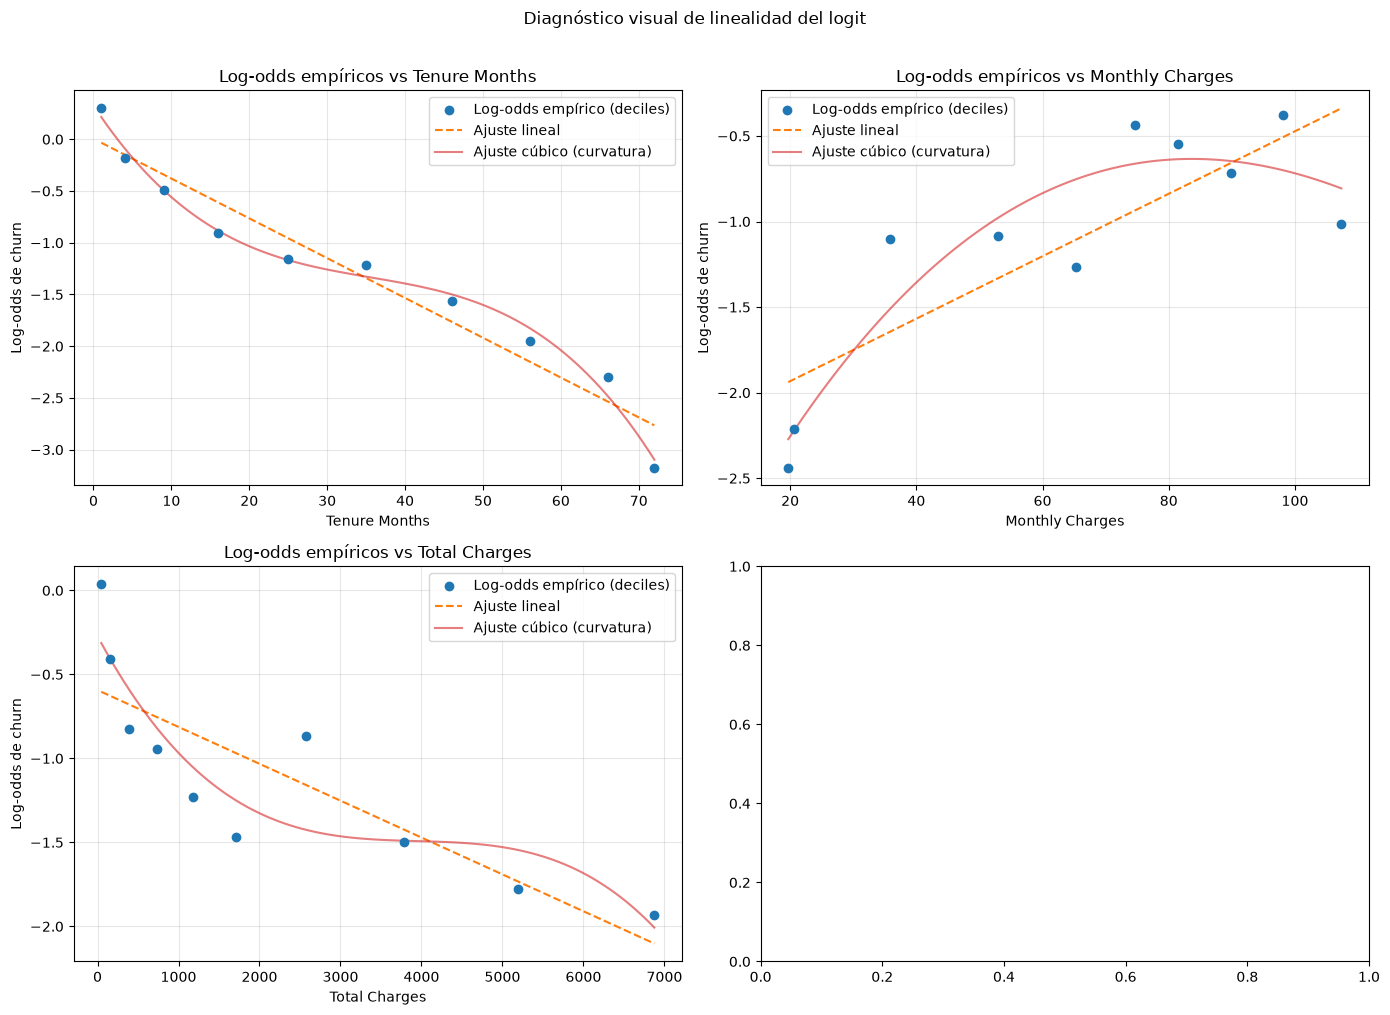

In [166]:
# log-odds empíricos por deciles (verificación visual)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for eje, var in zip(axes.ravel(), continuas):
    datos = pd.DataFrame({
        "x": X_train_dm[var].to_numpy(),
        "y": y_train.to_numpy(),
    })
    datos["decil"] = pd.qcut(datos["x"], q=10, duplicates="drop")

    agregado = datos.groupby("decil", observed=True).agg(
        n=("y", "size"),
        x_mediana=("x", "median"),
        eventos=("y", "sum"),
    )
    # Corrección de 0.5 para evitar log(0) en grupos sin eventos
    agregado["logit_empirico"] = np.log(
        (agregado["eventos"] + 0.5) / (agregado["n"] - agregado["eventos"] + 0.5)
    )

    x_graf = agregado["x_mediana"].to_numpy()
    y_graf = agregado["logit_empirico"].to_numpy()

    # Ajuste lineal (grado 1) y curvo (grado 3) para comparar visualmente
    orden1 = np.polyfit(x_graf, y_graf, 1)
    orden3 = np.polyfit(x_graf, y_graf, 3)
    x_linea = np.linspace(x_graf.min(), x_graf.max(), 100)

    eje.scatter(x_graf, y_graf, color="tab:blue", zorder=3,
                label="Log-odds empírico (deciles)")
    eje.plot(x_linea, np.polyval(orden1, x_linea), color="tab:orange",
             linestyle="--", label="Ajuste lineal")
    eje.plot(x_linea, np.polyval(orden3, x_linea), color="tab:red",
             alpha=0.6, label="Ajuste cúbico (curvatura)")
    eje.set_title(f"Log-odds empíricos vs {var}")
    eje.set_xlabel(var)
    eje.set_ylabel("Log-odds de churn")
    eje.legend()
    eje.grid(alpha=0.3)

plt.suptitle("Diagnóstico visual de linealidad del logit", y=1.01)
plt.tight_layout()
plt.show()

Los gráficos muestran que Tenure Months presenta la mayor desviación respecto a una relación lineal con el logit. La curva cúbica se aparta de la recta especialmente en los valores bajos y altos de permanencia, lo que sugiere una relación no estrictamente lineal.

En conjunto, el diagnóstico visual indica que el supuesto de linealidad del logit se cumple de forma aceptable para Total Charges y CLTV, mientras que Tenure Months y, en menor medida, Monthly Charges muestran cierta curvatura, consistente con un posible incumplimiento parcial del supuesto.

Si el objetivo fuera mejorar la interpretación del modelo, podría considerarse incorporar transformaciones (por ejemplo, logaritmos o splines restringidos) para Tenure Months y Monthly Charges, o reducir la redundancia entre variables altamente correlacionadas. No obstante, las desviaciones observadas son moderadas y **no invalidan el uso del modelo**, aunque sí sugieren interpretar con cautela los coeficientes asociados a estas variables.

## Supuesto 4 - Sin multicolinealidad grave
Exige que los predictores no esten fuertemente relacionados entre si. La multicolinealidad puede volver inestables los coeficientes individuales, pero no implica por si sola que las predicciones sean malas, especialmente cuando se usa regularizacion.

El VIF se calcula sobre la matriz de diseño final, que contiene solo los nueve predictores permitidos. Las variables de servicios excluidas por diseño no forman parte de este diagnostico.


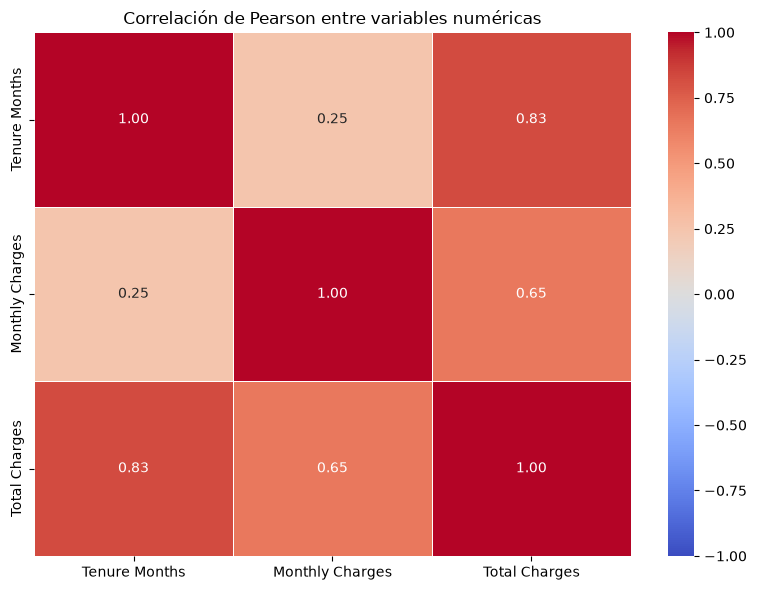

In [167]:
correlaciones = X_train_dm[continuas].corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Correlación de Pearson entre variables numéricas")
plt.tight_layout()
plt.show()

VIF del diseño final:
                             Predictor   VIF
                       Monthly Charges 12.01
                         Total Charges 10.15
                         Tenure Months  7.40
          Internet Service_Fiber optic  4.11
                   Internet Service_No  3.54
                     Contract_Two year  2.50
       Payment Method_Electronic check  1.99
           Payment Method_Mailed check  1.91
Payment Method_Credit card (automatic)  1.58
                     Contract_One year  1.55
                           Partner_Yes  1.34
                        Dependents_Yes  1.22
                 Paperless Billing_Yes  1.21

Predictores con VIF > 5: 3
Predictores con VIF > 10: 2


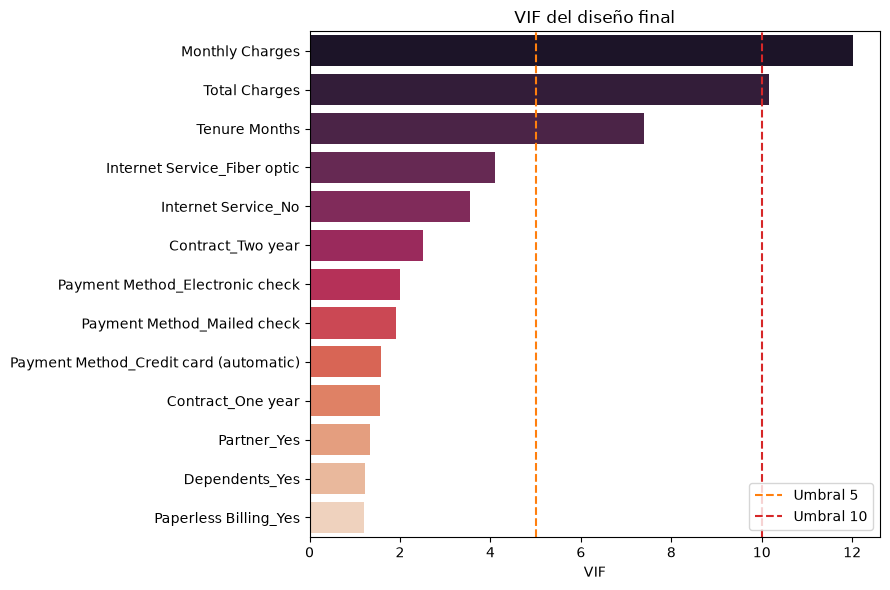

In [168]:
# VIF sobre el diseño final con intercepto.
# Solo se incluyen las columnas de los nueve predictores permitidos.
matriz_vif = X_train_sm.to_numpy()
nombres_vif = list(X_train_sm.columns)
valores_vif = [variance_inflation_factor(matriz_vif, i) for i in range(matriz_vif.shape[1])]
tabla_vif = pd.DataFrame({'Predictor': nombres_vif, 'VIF': valores_vif})
tabla_vif = tabla_vif[tabla_vif['Predictor'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)
n_vif_5 = int((tabla_vif['VIF'] > 5).sum())
n_vif_10 = int((tabla_vif['VIF'] > 10).sum())
print('VIF del diseño final:')
print(tabla_vif.round(2).to_string(index=False))
print(f'\nPredictores con VIF > 5: {n_vif_5}')
print(f'Predictores con VIF > 10: {n_vif_10}')
plt.figure(figsize=(9, 6))
sns.barplot(data=tabla_vif, x='VIF', y='Predictor', hue='Predictor', palette='rocket', legend=False)
plt.axvline(5, color='tab:orange', linestyle='--', label='Umbral 5')
plt.axvline(10, color='tab:red', linestyle='--', label='Umbral 10')
plt.title('VIF del diseño final')
plt.xlabel('VIF')
plt.ylabel('')
plt.legend()
plt.tight_layout()
plt.show()


El VIF se interpreta sobre el conjunto de predictores permitido. Si aparece colinealidad entre variables numericas o dummies de `Internet Service`, esta afecta principalmente la atribucion de un efecto aislado a cada coeficiente. La regresion logistica sigue permitiendo explicar cada puntuacion como una suma ponderada de las variables, pero no conviene interpretar cada coeficiente como un efecto causal independiente.


## Supuesto 5 - Tamaño muestral suficiente
El EPV es una heuristica que relaciona el numero de eventos con el numero de parámetros estimados sin contar el intercepto. Se reporta sobre el diseño final de 13 parámetros codificados, no sobre todas las columnas disponibles despues de la limpieza.


In [169]:
n_eventos = int(y_train.sum())
n_no_eventos = int((y_train == 0).sum())
n_parametros = X_train_dm.shape[1]  # sin intercepto

epv = n_eventos / n_parametros
epv_no_eventos = n_no_eventos / n_parametros

print(f"Eventos (churners) en entrenamiento:\t{n_eventos}")
print(f"No eventos (permanentes):\t\t{n_no_eventos}")
print(f"Número de parámetros estimados (k):\t{n_parametros}")
print(f"EPV  = eventos / k = {n_eventos} / {n_parametros} =\t{epv:.2f}")
print(f"Ratio no-eventos / k = \t\t\t{epv_no_eventos:.2f}")
print(f"Umbral heurístico EPV >= 10:\t\t{'CUMPLE' if epv >= 10 else 'NO CUMPLE'}")

Eventos (churners) en entrenamiento:	1308
No eventos (permanentes):		3622
Número de parámetros estimados (k):	13
EPV  = eventos / k = 1308 / 13 =	100.62
Ratio no-eventos / k = 			278.62
Umbral heurístico EPV >= 10:		CUMPLE


- El EPV se calcula con el numero de eventos del entrenamiento y los parámetros codificados del diseño final.
- Un EPV por encima de 10 indica que no hay una senal de falta de eventos para estimar este modelo.
- El EPV es una regla practica y no sustituye la validacion predictiva ni la calibración.


## Supuesto 6 - Sin atípicos influyentes
Los atípicos influyentes importan si representan errores de datos o si cambian mucho el ajuste. Se revisan leverage, distancia de Cook y DFBETAS sobre el mismo diseño de 13 parámetros que se usa para el modelo.


In [170]:
modelo_glm = sm.GLM(
    y_train,
    X_train_sm,
    family=sm.families.Binomial(),
)
res_glm = modelo_glm.fit()

influencia = res_glm.get_influence()
leverage = influencia.hat_matrix_diag
cooks = influencia.cooks_distance[0]
dfbetas = np.asarray(influencia.dfbetas)

n_obs = X_train_dm.shape[0]
p_params = X_train_dm.shape[1] + 1  # + intercepto

umbral_leverage = 2 * p_params / n_obs
umbral_cook = 4 / n_obs
umbral_dfbetas = 2 / np.sqrt(n_obs)

n_leverage = int((leverage > umbral_leverage).sum())
n_cook = int((cooks > umbral_cook).sum())
n_dfbetas = int((np.abs(dfbetas) > umbral_dfbetas).sum())
n_cook_grave = int((cooks > 1).sum())

print(f"Observaciones en entrenamiento: {n_obs}")
print(f"Umbral leverage\t(2p/n):\t\t{umbral_leverage:.4f}\t\tpuntos: {n_leverage}")
print(f"Umbral Cook\t(4/n):\t\t{umbral_cook:.6f}\tpuntos: {n_cook}")
print(f"Umbral |DFBETAS|(2/raizn):\t{umbral_dfbetas:.4f}\t\tceldas: {n_dfbetas}") # tocó copiar y pegar el simbolo raiz
print(f"Cook > 1 (grave):\t\t\t\tpuntos: {n_cook_grave}")

Observaciones en entrenamiento: 4930
Umbral leverage	(2p/n):		0.0057		puntos: 278
Umbral Cook	(4/n):		0.000811	puntos: 282
Umbral |DFBETAS|(2/raizn):	0.0285		celdas: 3774
Cook > 1 (grave):				puntos: 0


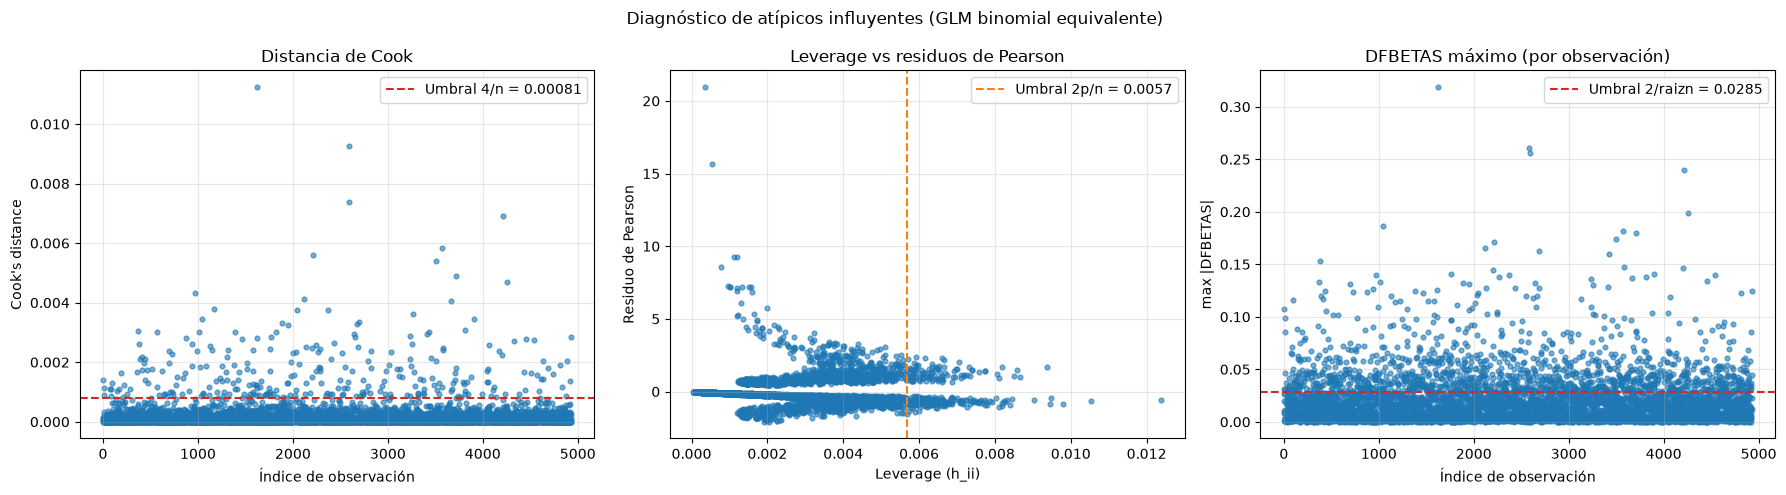

In [171]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Distancia de Cook por índice de observación
ejes[0].scatter(range(n_obs), cooks, s=12, alpha=0.6)
ejes[0].axhline(umbral_cook, color="tab:red", linestyle="--",
                label=f"Umbral 4/n = {umbral_cook:.5f}")
ejes[0].set_title("Distancia de Cook")
ejes[0].set_xlabel("Índice de observación")
ejes[0].set_ylabel("Cook's distance")
ejes[0].legend()
ejes[0].grid(alpha=0.3)

# 2) Leverage vs residuos de Pearson
p_ajustada = res_glm.fittedvalues.to_numpy()
residuos_pearson = (
    (y_train.to_numpy() - p_ajustada)
    / np.sqrt(p_ajustada * (1 - p_ajustada))
)
ejes[1].scatter(leverage, residuos_pearson, s=12, alpha=0.6)
ejes[1].axvline(umbral_leverage, color="tab:orange", linestyle="--",
                label=f"Umbral 2p/n = {umbral_leverage:.4f}")
ejes[1].set_title("Leverage vs residuos de Pearson")
ejes[1].set_xlabel("Leverage (h_ii)")
ejes[1].set_ylabel("Residuo de Pearson")
ejes[1].legend()
ejes[1].grid(alpha=0.3)

# 3) DFBETAS máximo absoluto por observación
dfbetas_max = np.abs(dfbetas).max(axis=1)
ejes[2].scatter(range(n_obs), dfbetas_max, s=12, alpha=0.6)
ejes[2].axhline(umbral_dfbetas, color="tab:red", linestyle="--",
                label=f"Umbral 2/raizn = {umbral_dfbetas:.4f}") # tocó copiar y pegar el simbolo raiz
ejes[2].set_title("DFBETAS máximo (por observación)")
ejes[2].set_xlabel("Índice de observación")
ejes[2].set_ylabel("max |DFBETAS|")
ejes[2].legend()
ejes[2].grid(alpha=0.3)

plt.suptitle("Diagnóstico de atípicos influyentes (GLM binomial equivalente)")
plt.tight_layout()
plt.show()

Ninguna observación tiene $\text{Cook} > 1$ (0 puntos), así que no hay casos que sesguen gravemente el ajuste. En la banda de influencia `Cook > 4/n` caen 272 de  4922 puntos ($\approx 5.5 \%$), y en `leverage > 2p/n` 317 ($\approx 6.4 \%$). Es una proporción esperable y pequeña, los umbrales están diseñados justamente para marcar una cola reducida de puntos.

## Conclusiones


Se decidió hacer una tabla con los valores obtenidos de los supuestos para mantener reproducibilidad cada vez que se experimentaba con el dataset y ver como cambiaba en cada ejecución.

In [172]:
resumen = pd.DataFrame([
    {
        "Supuesto": "1. Observaciones independientes",
        "Diagnostico": "Diseño transversal + duplicados / unicidad de ID",
        "Resultado": (
            f"{n_duplicados} duplicadas; "
            f"{n_ids_unicos}/{n_filas} IDs únicos"
        ),
        "Se cumple": "Sí" if
                     (n_duplicados == 0 and n_ids_unicos == n_filas) else "Revisar",
    },
    {
        "Supuesto": "2. Variable objetivo adecuada",
        "Diagnostico": "Inspección de valores únicos y proporción",
        "Resultado": (
            f"valores={valores_unicos}; churn={y_train.mean()*100:.2f}%"
        ),
        "Se cumple": "Sí" if valores_unicos == [0, 1] else "No",
    },
    {
        "Supuesto": "3. Linealidad del logit",
        "Diagnostico": "Box-Tidwell (interacciones x*ln x) + deciles",
        "Resultado": (
            f"interacciones con p>0.05: "
            f"{int(tabla_bt['Linealidad_ok_p>0.05'].sum())}/{len(tabla_bt)}; "
            f"Wald conjunto p={p_value_conjunto:.4f}"
        ),
        "Se cumple": "Sí" if tabla_bt["Linealidad_ok_p>0.05"].all() else "Parcial / revisar",
    },
    {
        "Supuesto": "4. Sin multicolinealidad grave",
        "Diagnostico": "VIF por predictor + correlaciones",
        "Resultado": (
            f"máx VIF={tabla_vif['VIF'].max():.2f} "
            f"({tabla_vif.iloc[0]['Predictor']}); VIF>10: {n_vif_10}"
        ),
        "Se cumple": "Sí" if n_vif_10 == 0 else "Parcial",
    },
    {
        "Supuesto": "5. Tamaño muestral suficiente",
        "Diagnostico": "Heurística EPV >= 10",
        "Resultado": f"EPV={epv:.2f} ({n_eventos} eventos / {n_parametros} k)",
        "Se cumple": "Sí" if epv >= 10 else "No",
    },
    {
        "Supuesto": "6. Sin atípicos influyentes",
        "Diagnostico": "Leverage, Cook y DFBETAS",
        "Resultado": (
            f"leverage>{umbral_leverage:.3f}: {n_leverage}; "
            f"Cook>4/n: {n_cook}; Cook>1: {n_cook_grave}"
        ),
        "Se cumple": "Sí" if n_cook_grave == 0 else "Revisar",
    },
])

print("RESUMEN DE SUPUESTOS DE LA REGRESIÓN LOGÍSTICA")
print("=" * 177)
print(resumen.to_string(index=False))

RESUMEN DE SUPUESTOS DE LA REGRESIÓN LOGÍSTICA
                       Supuesto                                      Diagnostico                                             Resultado         Se cumple
1. Observaciones independientes Diseño transversal + duplicados / unicidad de ID                    0 duplicadas; 7043/7043 IDs únicos                Sí
  2. Variable objetivo adecuada        Inspección de valores únicos y proporción                          valores=[0, 1]; churn=26.53%                Sí
        3. Linealidad del logit     Box-Tidwell (interacciones x*ln x) + deciles interacciones con p>0.05: 1/3; Wald conjunto p=0.0000 Parcial / revisar
 4. Sin multicolinealidad grave                VIF por predictor + correlaciones            máx VIF=12.01 (Monthly Charges); VIF>10: 2           Parcial
  5. Tamaño muestral suficiente                             Heurística EPV >= 10                      EPV=100.62 (1308 eventos / 13 k)                Sí
    6. Sin atípicos influyentes    

- **Supuesto 1 (independencia): Se sostiene razonablemente.** Hay un registro por cliente, no hay duplicados exactos y los IDs son únicos.
- **Supuesto 2 (objetivo binario): Se cumple.** `Churn Value` toma los valores 0 y 1.
- **Supuesto 3 (linealidad del logit): Se cumple parcialmente.** Hay curvatura visible en `Tenure Months`. Se comparan alternativas no lineales con la misma validacion cruzada para saber si esa desviacion cambia `Precision@15`.
- **Supuesto 4 (multicolinealidad): Se evalua sobre el modelo correcto.** Los VIF ya no incluyen las variables de servicios excluidas por diseño. La colinealidad restante se interpreta como un problema de estabilidad e interpretacion aislada, no como evidencia suficiente de mala predicción.
- **Supuesto 5 (tamaño muestral): Se cumple.** El EPV se calcula con los aproximadamente 13 parámetros del diseño final y los eventos del entrenamiento.
- **Supuesto 6 (atípicos influyentes): No hay evidencia de casos graves.** No se observan puntos con Cook mayor que 1 y no se eliminan observaciones sin una razon de calidad de datos.
- **Calibración: debe reportarse junto con el ordenamiento.** La curva de calibración, Brier y ECE permiten valorar si `p_churn` es apropiada para el calculo de utilidad.
